# 06 — Genetic programming per β(t): esperimento sulla seconda ondata

**Prima di questo notebook: il notebook 05** verifica su epidemie sintetiche (β vera nota) che cosa il GP sa ritrovare. Le conclusioni qui sotto valgono solo nei limiti che il notebook 05 mostra (ritardo identificabile? falsi positivi della mobilità?).

**Impostazione** (decisioni dell'11/11/2026):
- finestra **1/9/2020 – 31/1/2021**, training sui primi 2/3 (fino all'11/12/2020), test sul resto;
- **β(t) = β_cost · exp(g(x(t)))**, con g l'albero evoluto e β_cost il β della baseline costante; β limitata a [10⁻⁴, 2];
- **tre configurazioni di terminali**: solo `t` (in mesi); solo mobilità (`retail`, `work` con ritardi 0, 3, 7, 10, 14); entrambi;
- σ fisso (**1/4** di riferimento, **1/3** come sensibilità; la prova pilota era con 1/5,2), γ(t) e μ(t) dai dati, **E₀ stimato per ogni formula** come nelle baseline;
- NSGA-II su (errore normalizzato sul training, numero di nodi), (μ + λ) con 200 + 200 individui, 100 generazioni, crossover oppure mutazione, profondità ≤ 6, duplicati eliminati, costanti del front ottimizzate con Nelder-Mead ogni 5 generazioni;
- **10 seed** per configurazione e per σ (60 run);
- in più, 60 run (σ = 1/4 e σ = 1/3) con il **vincolo di plausibilità** |g| ≤ 2 su tutta la finestra (β fra β_cost/7,4 e β_cost·7,4), che scarta le formule con singolarità (sezione 5; sensibilità alla soglia nella sezione 1b).

Codice in `src/seird_gp/gp.py`; run con `scripts/run_gp.py` (circa 7 minuti l'una, 60 run in circa 4 ore con 2 core). Qui si leggono i Pareto front salvati in `results/gp/`.

**Regola per scegliere una formula per run** (fissata prima di guardare i risultati): la formula più semplice del Pareto front con errore di training entro il 5% del migliore di quella run. Usa solo il training: il test resta un controllo onesto. La regola del "gomito" è stata scartata dopo la prova pilota: con front di 3–7 formule sceglieva formule banali. (Lo script `run_gp.py` stampa ancora la formula al gomito: è solo un'anteprima, la scelta si fa qui sui front salvati.)

**Robustezza della regola** (sezione 1b): la soglia del 5% è arbitraria, quindi la scelta si ripete con soglie 0%, 2%, 5%, 10%, 20%, senza e con il vincolo. Le conclusioni valgono solo se non cambiano con la soglia.

In [1]:
import glob, json, pickle, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, RESULTS_DIR
from seird_gp.beta_models import load_restrictions

TOL = 0.05
SIGMA_KEYS = {"4": "σ = 1/4 (latenza)", "3": "σ = 1/3 (latenza, Europa)", "5.2": "σ = 1/5.2"}
CONFIG_ORDER = ["tempo", "mobilita", "tempo+mobilita"]

def load_runs(tag="full_"):
    rows = []
    for f in sorted(glob.glob(str(RESULTS_DIR / "gp" / f"{tag}*.json"))):
        m = re.search(r"_s([\d.]+)_(.+)_seed(\d+)\.json$", f)
        front = pd.DataFrame(json.load(open(f)))
        front["beta"] = front["beta"].apply(np.array)
        rows.append({"σ": m.group(1), "config": m.group(2), "seed": int(m.group(3)), "front": front})
    return pd.DataFrame(rows)

def choose(front, tol=TOL):
    ok = front[front["fitness_norm train"] <= (1 + tol) * front["fitness_norm train"].min()]
    return ok.sort_values(["nodi", "fitness_norm train"]).iloc[0]

def choose_all(runs, tol=TOL):
    return pd.DataFrame([{**{k: r[k] for k in ["σ", "config", "seed"]}, **choose(r["front"], tol).to_dict()}
                         for _, r in runs.iterrows()])

runs = load_runs("full_")          # senza vincolo
runs_v = load_runs("vinc_")        # con il vincolo |g| ≤ 2 (σ = 1/4 e 1/3)
chosen, chosen_v = choose_all(runs), choose_all(runs_v)
print(len(runs), "run senza vincolo;", runs.groupby(["σ", "config"]).size().to_dict())
print(len(runs_v), "run con vincolo;", runs_v.groupby(["σ", "config"]).size().to_dict())

60 run senza vincolo; {('3', 'mobilita'): 10, ('3', 'tempo'): 10, ('3', 'tempo+mobilita'): 10, ('4', 'mobilita'): 10, ('4', 'tempo'): 10, ('4', 'tempo+mobilita'): 10}
60 run con vincolo; {('3', 'mobilita'): 10, ('3', 'tempo'): 10, ('3', 'tempo+mobilita'): 10, ('4', 'mobilita'): 10, ('4', 'tempo'): 10, ('4', 'tempo+mobilita'): 10}


## 1. Il GP contro le baseline

Mediana e intervallo interquartile sui 10 seed della formula scelta, accanto alle baseline dello stesso σ (notebook 04).

In [2]:
base = pickle.load(open(RESULTS_DIR / "04_baseline_all.pkl", "rb"))
W = "set20–gen21"
rows = []
for s, key in SIGMA_KEYS.items():
    for m in ["costante", "a tratti", "lineare retail", "lineare work", "lineare retail+work"]:
        if (W, m, key) in base:
            r = base[(W, m, key)]
            rows.append({"σ": s, "modello": f"baseline {m}", "train": r.rmsd.loc["train", "fitness_norm"],
                         "test": r.rmsd.loc["test", "fitness_norm"], "test IQR": "", "nodi": ""})
    for c in CONFIG_ORDER:
        g = chosen[(chosen["σ"] == s) & (chosen["config"] == c)]
        if len(g):
            q = g["fitness_norm test"].quantile([.25, .75])
            rows.append({"σ": s, "modello": f"GP {c} (mediana su {len(g)} seed)",
                         "train": g["fitness_norm train"].median(), "test": g["fitness_norm test"].median(),
                         "test IQR": f"{q.iloc[0]:.2f}–{q.iloc[1]:.2f}", "nodi": int(g["nodi"].median())})
for (s, c), g in chosen_v.groupby(["σ", "config"]):
    if True:
        q = g["fitness_norm test"].quantile([.25, .75])
        rows.append({"σ": s, "modello": f"GP {c}, con vincolo (mediana su {len(g)} seed)",
                     "train": g["fitness_norm train"].median(), "test": g["fitness_norm test"].median(),
                     "test IQR": f"{q.iloc[0]:.2f}–{q.iloc[1]:.2f}", "nodi": int(g["nodi"].median())})
summary = pd.DataFrame(rows)
summary = summary.iloc[summary["σ"].map({"4": 0, "3": 1, "5.2": 2}).argsort(kind="stable")]  # σ = 1/4 prima
summary = summary[summary["σ"].isin(chosen["σ"].unique())].set_index(["σ", "modello"])
summary.to_csv(RESULTS_DIR / "06_gp_vs_baseline.csv")
summary.round(3)

train   test   test IQR  \
σ modello                                                                       
4 baseline costante                                   0.196  1.774              
  baseline a tratti                                   0.130  0.306              
  baseline lineare retail                             0.164  0.637              
  baseline lineare work                               0.139  0.726              
  baseline lineare retail+work                        0.120  1.050              
  GP tempo (mediana su 10 seed)                       0.130  0.968  0.44–1.01   
  GP mobilita (mediana su 10 seed)                    0.137  0.461  0.40–0.51   
  GP tempo+mobilita (mediana su 10 seed)              0.139  0.557  0.43–0.64   
  GP mobilita, con vincolo (mediana su 10 seed)       0.135  0.447  0.40–0.54   
  GP tempo, con vincolo (mediana su 10 seed)          0.154  0.932  0.85–0.93   
  GP tempo+mobilita, con vincolo (mediana su 10 s...  0.142  0.473  0.40–0.55   
3 baseline costante                                   0.192  1.649              
  baseline a tratti                                   0.130  0.305              
  baseline lineare retail                             0.165  0.662              
  baseline lineare work                               0.141  0.713              
  baseline lineare retail+work                        0.121  1.053              
  GP tempo (mediana su 10 seed)                       0.127  1.097  0.49–1.28   
  GP mobilita (mediana su 10 seed)                    0.129  0.556  0.49–0.65   
  GP tempo+mobilita (mediana su 10 seed)              0.140  0.537  0.42–1.26   
  GP mobilita, con vincolo (mediana su 10 seed)       0.142  0.464  0.40–0.61   
  GP tempo, con vincolo (mediana su 10 seed)          0.153  0.984  0.93–1.02   
  GP tempo+mobilita, con vincolo (mediana su 10 s...  0.142  0.499  0.37–0.57   

                                                     nodi  
σ modello                                                  
4 baseline costante                                        
  baseline a tratti                                        
  baseline lineare retail                                  
  baseline lineare work                                    
  baseline lineare retail+work                             
  GP tempo (mediana su 10 seed)                         8  
  GP mobilita (mediana su 10 seed)                      9  
  GP tempo+mobilita (mediana su 10 seed)                7  
  GP mobilita, con vincolo (mediana su 10 seed)         9  
  GP tempo, con vincolo (mediana su 10 seed)            7  
  GP tempo+mobilita, con vincolo (mediana su 10 s...    7  
3 baseline costante                                        
  baseline a tratti                                        
  baseline lineare retail                                  
  baseline lineare work                                    
  baseline lineare retail+work                             
  GP tempo (mediana su 10 seed)                        12  
  GP mobilita (mediana su 10 seed)                     10  
  GP tempo+mobilita (mediana su 10 seed)                8  
  GP mobilita, con vincolo (mediana su 10 seed)         9  
  GP tempo, con vincolo (mediana su 10 seed)            9  
  GP tempo+mobilita, con vincolo (mediana su 10 s...    6

## 1b. Sensibilità sulla soglia di scelta

La formula di ogni run si sceglie con una soglia: la più semplice con errore di training entro il `tol` del migliore della run. Il 5% è arbitrario, quindi qui la scelta si ripete con **tol = 0%, 2%, 5%, 10%, 20%**:
- **0%** = la formula migliore sul training (la più complessa, a rischio di overfitting);
- soglie crescenti = formule sempre più semplici.

Si fa per le run **senza e con il vincolo** |g| ≤ 2. Come prima, la scelta usa solo il training; il test serve solo a valutare.

**Criterio, fissato prima di guardare i risultati.** La regola è robusta se, per ogni σ (e con o senza vincolo), al variare di `tol`:
1. l'ordine delle tre configurazioni per errore di test mediano non cambia;
2. il confronto di ogni configurazione con le baseline (costante, migliore lineare, a tratti) non cambia: se il GP batte una baseline al 5%, la batte a tutte le soglie (e viceversa).

Se una delle due cose cambia, la conclusione corrispondente va riportata come dipendente dalla regola di scelta.


In [3]:
TOLS = [0.0, 0.02, 0.05, 0.10, 0.20]

rows = []
for vinc, rr in [("senza vincolo", runs), ("con vincolo", runs_v)]:
  for tol in TOLS:
    for _, r in rr.iterrows():
        f = choose(r["front"], tol)
        rows.append({"vincolo": vinc, "tol": tol, "σ": r["σ"], "config": r["config"], "seed": r["seed"],
                     "formula": f["formula"], "nodi": int(f["nodi"]),
                     "train": f["fitness_norm train"], "test": f["fitness_norm test"]})
sens = pd.DataFrame(rows)

# quota di run in cui la formula scelta è la stessa della soglia di riferimento (5%)
ref = sens[sens["tol"] == TOL].set_index(["vincolo", "σ", "config", "seed"])["formula"]
sens["come al 5%"] = [f == ref[(v, s, c, k)] for v, s, c, k, f in sens[["vincolo", "σ", "config", "seed", "formula"]].itertuples(index=False)]

agg = (sens.groupby(["vincolo", "σ", "config", "tol"])
       .agg(test_mediana=("test", "median"),
            test_q25=("test", lambda x: x.quantile(.25)),
            test_q75=("test", lambda x: x.quantile(.75)),
            test_peggiore=("test", "max"),
            nodi_mediana=("nodi", "median"),
            quota_come_5=("come al 5%", "mean"))
       .reset_index())
agg.to_csv(RESULTS_DIR / "06_sensibilita_soglia.csv", index=False)

def wide(col, fmt="{:.3f}"):
    t = agg.pivot_table(index=["vincolo", "σ", "config"], columns="tol", values=col)
    t.columns = [f"{c:.0%}" for c in t.columns]
    return t.reindex(CONFIG_ORDER, level="config")

print("Errore di test, mediana sui seed")
display(wide("test_mediana").round(3))
print("Errore di test, caso peggiore sui seed")
display(wide("test_peggiore").round(3))
print("Numero di nodi, mediana sui seed")
display(wide("nodi_mediana"))
print("Quota di run con la stessa formula scelta al 5%")
display(wide("quota_come_5").round(2))


Errore di test, mediana sui seed


0%     2%     5%    10%    20%
vincolo       σ config                                           
con vincolo   3 tempo           0.984  0.986  0.984  0.408  0.408
                mobilita        0.433  0.536  0.464  0.409  0.662
                tempo+mobilita  0.543  0.523  0.499  0.494  0.662
              4 tempo           0.930  0.932  0.932  0.448  0.664
                mobilita        0.495  0.495  0.447  0.476  0.566
                tempo+mobilita  0.467  0.501  0.473  0.464  0.779
senza vincolo 3 tempo           1.087  1.097  1.097  1.154  0.984
                mobilita        0.537  0.556  0.556  0.485  0.485
                tempo+mobilita  0.666  0.591  0.537  0.545  0.662
              4 tempo           0.967  0.968  0.968  0.395  0.705
                mobilita        0.500  0.493  0.461  0.461  0.499
                tempo+mobilita  0.615  0.597  0.557  0.540  0.779

Errore di test, caso peggiore sui seed


0%       2%       5%      10%    20%
vincolo       σ config                                                   
con vincolo   3 tempo             1.905    1.905    1.905    1.457  1.457
                mobilita          0.703    0.703    0.673    0.673  0.673
                tempo+mobilita    0.732    0.732    0.732    0.732  0.662
              4 tempo             1.652    1.652    1.589    1.589  1.780
                mobilita          0.791    0.791    0.791    0.791  0.779
                tempo+mobilita    0.779    0.779    0.790    0.779  1.779
senza vincolo 3 tempo           150.066  150.066  150.066  150.066  1.380
                mobilita          1.047    1.047    1.047    0.573  0.662
                tempo+mobilita   45.124   22.298    9.391    9.391  5.562
              4 tempo             1.299    1.201    1.018    1.018  1.310
                mobilita          0.787    0.787    0.787    0.528  0.779
                tempo+mobilita    2.963    2.963    2.963    2.963  2.963

Numero di nodi, mediana sui seed


0%    2%    5%   10%  20%
vincolo       σ config                                     
con vincolo   3 tempo           10.0  10.0   9.5   5.0  5.0
                mobilita        12.5  10.5   9.0   6.5  4.0
                tempo+mobilita  11.5   7.0   6.5   6.0  3.0
              4 tempo            9.0   8.5   7.0   5.0  5.0
                mobilita        12.0  11.0   9.0   7.0  5.0
                tempo+mobilita   9.0   9.0   7.0   5.0  3.0
senza vincolo 3 tempo           14.0  12.5  12.5  10.0  7.0
                mobilita        11.5  11.5  10.0   7.0  5.0
                tempo+mobilita  12.0   9.0   8.0   8.0  3.0
              4 tempo           15.0   9.0   8.0   8.0  5.0
                mobilita        13.0  12.0   9.0   7.0  5.0
                tempo+mobilita  12.5  12.0   7.0   6.5  4.0

Quota di run con la stessa formula scelta al 5%


0%   2%   5%  10%  20%
vincolo       σ config                                 
con vincolo   3 tempo           0.7  0.8  1.0  0.2  0.2
                mobilita        0.4  0.5  1.0  0.7  0.2
                tempo+mobilita  0.6  0.8  1.0  0.7  0.0
              4 tempo           0.3  0.7  1.0  0.6  0.2
                mobilita        0.6  0.6  1.0  0.5  0.1
                tempo+mobilita  0.5  0.6  1.0  0.6  0.0
senza vincolo 3 tempo           0.8  1.0  1.0  0.8  0.3
                mobilita        0.7  0.8  1.0  0.5  0.0
                tempo+mobilita  0.5  0.8  1.0  0.7  0.0
              4 tempo           0.5  0.9  1.0  0.6  0.1
                mobilita        0.3  0.4  1.0  0.6  0.1
                tempo+mobilita  0.4  0.6  1.0  0.6  0.2

Verifica del criterio: per ogni σ e soglia, l'ordine delle configurazioni e il confronto con le baseline (✓ = GP migliore della baseline sul test, ✗ = peggiore). Le baseline vengono da `results/04_baseline_all.pkl` (sezione 1); se per un σ mancano, la colonna resta vuota.


In [4]:
LINEARI = ["lineare retail", "lineare work", "lineare retail+work"]

def baseline_test(s):
    key = SIGMA_KEYS[s]
    get = lambda m: base[(W, m, key)].rmsd.loc["test", "fitness_norm"] if (W, m, key) in base else np.nan
    lin = [get(m) for m in LINEARI]
    return {"costante": get("costante"),
            "migliore lineare": np.nanmin(lin) if not np.all(np.isnan(lin)) else np.nan,
            "a tratti": get("a tratti")}

def mark(gp, b):
    return "" if np.isnan(b) else ("✓" if gp < b else "✗")

check = []
for (v, s, tol), g in agg.groupby(["vincolo", "σ", "tol"]):
    med = g.set_index("config")["test_mediana"].reindex(CONFIG_ORDER).dropna()
    b = baseline_test(s)
    row = {"vincolo": v, "σ": s, "soglia": f"{tol:.0%}", "ordine (test mediano)": " < ".join(med.sort_values().index)}
    for c in med.index:
        for name, v in b.items():
            row[f"{c} vs {name}"] = mark(med[c], v)
    check.append(row)
check = pd.DataFrame(check).set_index(["vincolo", "σ", "soglia"])

stable = check.groupby(level=["vincolo", "σ"]).nunique().eq(1).T
stable.columns = [f"{v}, σ = 1/{s}" for v, s in stable.columns]
print("Criterio rispettato (True = uguale a tutte le soglie):")
display(stable)
check.T


Criterio rispettato (True = uguale a tutte le soglie):


,"con vincolo, σ = 1/3","con vincolo, σ = 1/4","senza vincolo, σ = 1/3","senza vincolo, σ = 1/4"
ordine (test mediano),False,False,False,False
tempo vs costante,True,True,True,True
tempo vs migliore lineare,False,False,True,False
tempo vs a tratti,True,True,True,True
mobilita vs costante,True,True,True,True
mobilita vs migliore lineare,False,True,True,True
mobilita vs a tratti,True,True,True,True
tempo+mobilita vs costante,True,True,True,True
tempo+mobilita vs migliore lineare,False,False,False,False
tempo+mobilita vs a tratti,True,True,True,True


vincolo                                                   con vincolo  \
σ                                                                   3   
soglia                                                             0%   
ordine (test mediano)               mobilita < tempo+mobilita < tempo   
tempo vs costante                                                   ✓   
tempo vs migliore lineare                                           ✗   
tempo vs a tratti                                                   ✗   
mobilita vs costante                                                ✓   
mobilita vs migliore lineare                                        ✓   
mobilita vs a tratti                                                ✗   
tempo+mobilita vs costante                                          ✓   
tempo+mobilita vs migliore lineare                                  ✓   
tempo+mobilita vs a tratti                                          ✗   

vincolo                                                                \
σ                                                                       
soglia                                                             2%   
ordine (test mediano)               tempo+mobilita < mobilita < tempo   
tempo vs costante                                                   ✓   
tempo vs migliore lineare                                           ✗   
tempo vs a tratti                                                   ✗   
mobilita vs costante                                                ✓   
mobilita vs migliore lineare                                        ✓   
mobilita vs a tratti                                                ✗   
tempo+mobilita vs costante                                          ✓   
tempo+mobilita vs migliore lineare                                  ✓   
tempo+mobilita vs a tratti                                          ✗   

vincolo                                                                \
σ                                                                       
soglia                                                             5%   
ordine (test mediano)               mobilita < tempo+mobilita < tempo   
tempo vs costante                                                   ✓   
tempo vs migliore lineare                                           ✗   
tempo vs a tratti                                                   ✗   
mobilita vs costante                                                ✓   
mobilita vs migliore lineare                                        ✓   
mobilita vs a tratti                                                ✗   
tempo+mobilita vs costante                                          ✓   
tempo+mobilita vs migliore lineare                                  ✓   
tempo+mobilita vs a tratti                                          ✗   

vincolo                                                                \
σ                                                                       
soglia                                                            10%   
ordine (test mediano)               tempo < mobilita < tempo+mobilita   
tempo vs costante                                                   ✓   
tempo vs migliore lineare                                           ✓   
tempo vs a tratti                                                   ✗   
mobilita vs costante                                                ✓   
mobilita vs migliore lineare                                        ✓   
mobilita vs a tratti                                                ✗   
tempo+mobilita vs costante                                          ✓   
tempo+mobilita vs migliore lineare                                  ✓   
tempo+mobilita vs a tratti                                          ✗   

vincolo                                                                \
σ                                                                       
soglia                                                

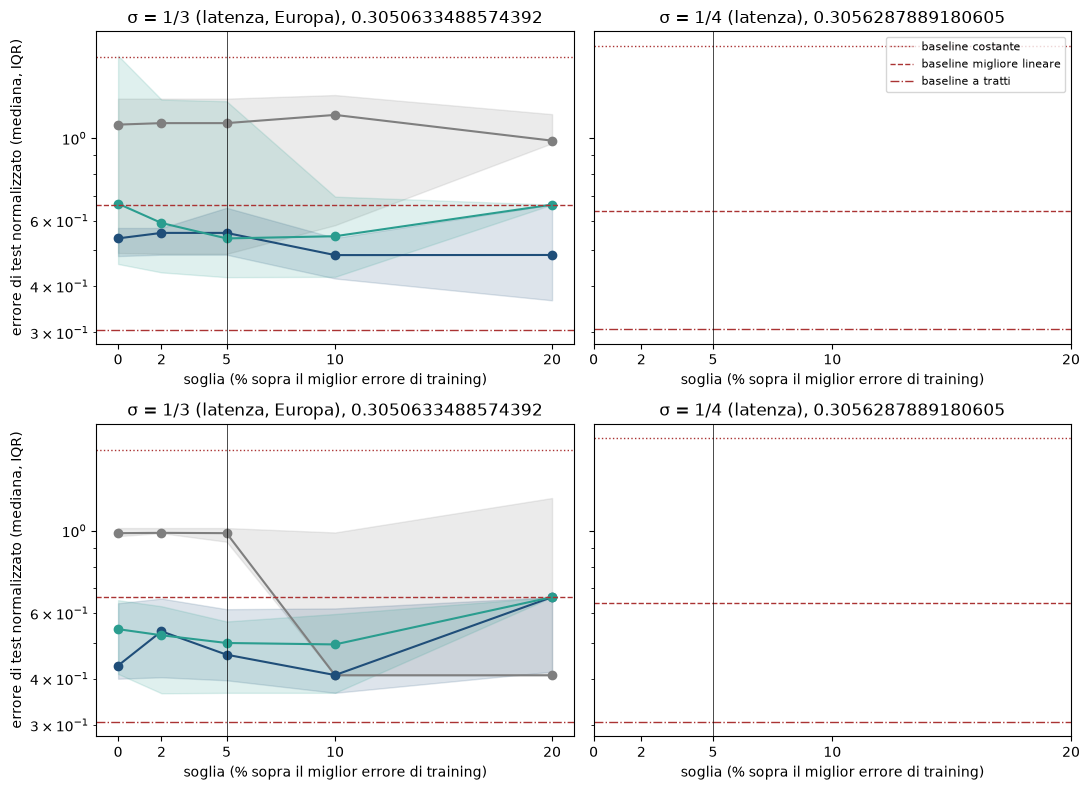

In [5]:
sigmas = sorted(agg["σ"].unique(), key=float)
VINC = ["senza vincolo", "con vincolo"]
fig, axes = plt.subplots(len(VINC), len(sigmas), figsize=(5.5 * len(sigmas), 4 * len(VINC)), sharey=True, squeeze=False)
colors = {"tempo": "#7f7f7f", "mobilita": "#1f4e79", "tempo+mobilita": "#2a9d8f"}
styles = {"costante": ":", "migliore lineare": "--", "a tratti": "-."}
x = np.array(TOLS) * 100
for i, v in enumerate(VINC):
    for ax, s in zip(axes[i], sigmas):
        for c in CONFIG_ORDER:
            g = agg[(agg["vincolo"] == v) & (agg["σ"] == s) & (agg["config"] == c)].sort_values("tol")
            if len(g):
                ax.plot(x, g["test_mediana"], "o-", color=colors[c], label=f"GP {c}")
                ax.fill_between(x, g["test_q25"], g["test_q75"], color=colors[c], alpha=0.15)
        for name, v in baseline_test(s).items():
            if not np.isnan(v):
                ax.axhline(v, color="#a33", ls=styles[name], lw=1, label=f"baseline {name}")
        ax.axvline(TOL * 100, color="black", lw=0.5)
        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xlabel("soglia (% sopra il miglior errore di training)")
        ax.set_title(f"{SIGMA_KEYS[s]}, {v}")
for row in axes:
    row[0].set_ylabel("errore di test normalizzato (mediana, IQR)")
axes[0][-1].legend(fontsize=8, loc="upper right")
plt.tight_layout()


**Lettura.** Il criterio è rispettato solo in parte: alcune conclusioni non dipendono dalla soglia, altre sì.

**Robuste (uguali a tutte le soglie, con e senza vincolo, con entrambi i σ):**
- ogni configurazione del GP batte la baseline costante;
- nessuna configurazione batte la baseline a tratti (sul perché, vedi la lettura nella sezione 6);
- il GP con la sola mobilità batte la migliore baseline lineare, con una sola eccezione: σ = 1/3 con vincolo e soglia 20%, dove il test è 0.662 in entrambi i casi (pari). Il suo test mediano resta fra 0.41 e 0.66 a tutte le soglie.

**Dipendenti dalla soglia:**
- **l'ordine delle configurazioni** cambia in tutti e quattro i casi. Il motivo principale è il solo tempo: con soglia 10% la sua mediana scende da 0.93–1.10 a 0.40–0.45 (in 3 casi su 4) perché la regola sceglie formule più semplici, fra cui il calo quadratico; è il risultato più instabile. Fra mobilità e tempo + mobilità le differenze sono piccole (pochi centesimi) e l'ordine si scambia;
- **tempo + mobilità contro la migliore lineare**: la batte fra il 2% e il 10%, non sempre agli estremi. Allo 0% (senza vincolo, σ = 1/3) pesano le formule più complesse; al 20% la regola sceglie formule di 3 nodi, cioè quasi la baseline lineare stessa;
- **il caso peggiore senza vincolo** dipende molto dalla soglia (solo tempo con σ = 1/3: 150 fino al 10%, 1.4 al 20%; tempo + mobilità con σ = 1/3: da 45 allo 0% a 5.6 al 20%); con il vincolo resta sotto 1.9 a tutte le soglie.

**Conseguenza per il paper.** Si possono affermare "GP meglio della costante", "GP con la mobilità meglio di una relazione lineare imposta" e "la baseline a tratti resta migliore sul test"; non si può affermare un ordine fra le tre configurazioni, e in particolare "la mobilità prevede meglio del tempo" vale solo per soglie fino al 5%.


## 2. Le formule scelte

Una riga per run. `ritardi` = ritardi della mobilità usati dalla formula.

In [6]:
def lags(terms):
    return sorted({int(t.split("lag")[1]) for t in terms if "lag" in t})

chosen["ritardi"] = chosen["terminali usati"].apply(lags)
chosen["usa t"] = chosen["terminali usati"].apply(lambda t: "t" in t)
cols = ["σ", "config", "seed", "nodi", "formula", "fitness_norm train", "fitness_norm test", "E0", "ritardi", "usa t"]
chosen.sort_values(["σ", "config", "seed"])[cols].round(3)

,σ,config,seed,nodi,formula,fitness_norm train,fitness_norm test,E0,ritardi,usa t
0,3,mobilita,1,20,"sub(sub(add(0.3084, add(work_lag7, work_lag0))...",0.121,0.835,281.748,"[0, 3, 7, 10, 14]",False
2,3,mobilita,2,6,"add(neg(1.5685), div(retail_lag7, work_lag3))",0.138,0.479,711.350,"[3, 7]",False
3,3,mobilita,3,5,"sub(mul(work_lag7, 2.6608), -0.5078)",0.141,0.544,53.093,[7],False
4,3,mobilita,4,11,"sub(add(0.1599, sub(work_lag3, mul(add(work_la...",0.144,0.382,43.561,"[0, 3]",False
5,3,mobilita,5,12,"mul(div(add(add(retail_lag7, retail_lag14), ne...",0.123,0.507,212.160,"[3, 7, 14]",False
6,3,mobilita,6,11,"sub(sub(-0.0719, 0.7201), div(sub(-0.6527, wor...",0.120,0.573,321.013,"[3, 7]",False
7,3,mobilita,7,9,"mul(sub(3.8655, div(-1.2159, work_lag14)), sub...",0.126,1.047,29.128,"[3, 14]",False
8,3,mobilita,8,5,"add(work_lag3, sub(work_lag3, -0.4132))",0.142,0.366,41.951,[3],False
9,3,mobilita,9,18,"add(mul(mul(9.2415, retail_lag10), sub(-0.2165...",0.120,0.568,153.265,"[0, 3, 10, 14]",False
1,3,mobilita,10,9,"add(sub(work_lag10, add(-0.4411, retail_lag3))...",0.132,0.675,136.801,"[3, 10]",False


## 3. Quali ritardi della mobilità sceglie il GP

Criterio del notebook 03, fissato prima dei risultati: se il GP usa di solito ritardi di 0–3 giorni il modello è coerente; se usa di solito 7 giorni o più manca il ritardo di notifica. Si guarda la distribuzione sui seed, non una singola run.

In [7]:
mob = chosen[chosen["config"] != "tempo"].copy()
mob["ritardo minimo"] = mob["ritardi"].apply(lambda l: min(l) if l else np.nan)
mob["ritardo massimo"] = mob["ritardi"].apply(lambda l: max(l) if l else np.nan)
counts = (mob.explode("ritardi").dropna(subset=["ritardi"])
          .groupby(["σ", "config", "ritardi"]).size().unstack(fill_value=0))
print("Formule che usano almeno un indice di mobilità:", int(mob["ritardi"].apply(bool).sum()), "su", len(mob))
print("Quota con tutti i ritardi ≤ 3 giorni:", round((mob["ritardo massimo"] <= 3).mean(), 2))
print("Quota con almeno un ritardo ≥ 7 giorni:", round((mob["ritardo massimo"] >= 7).mean(), 2))
counts

Formule che usano almeno un indice di mobilità: 40 su 40
Quota con tutti i ritardi ≤ 3 giorni: 0.38
Quota con almeno un ritardo ≥ 7 giorni: 0.62


ritardi           0   3   7   10  14
σ config                            
3 mobilita         3   9   5   3   4
  tempo+mobilita   6   5   1   6   4
4 mobilita         7   9   1   1   3
  tempo+mobilita   3   6   5   2   3

## 4. β(t) delle formule scelte

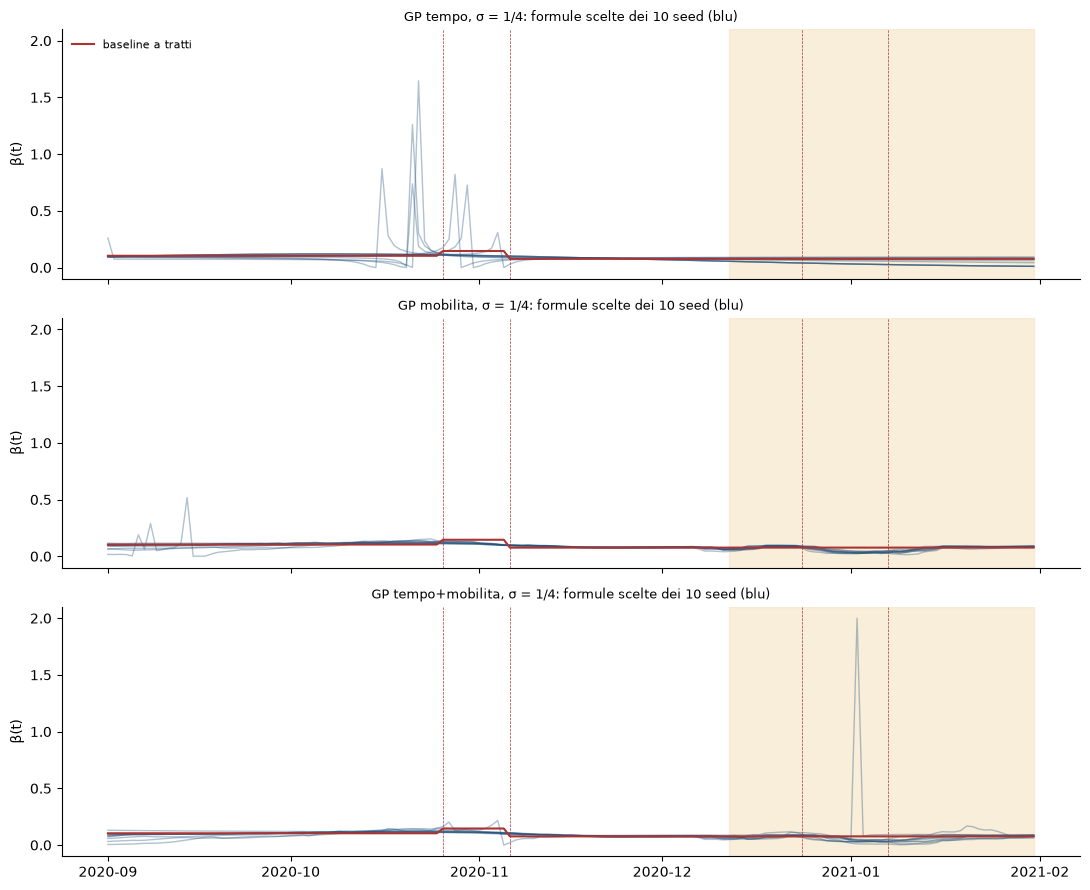

In [8]:
data = pd.read_csv(PROCESSED_DIR / "trento_clean.csv", index_col=0, parse_dates=True)
idx = data.loc["2020-09-01":"2021-01-31"].index
restr = load_restrictions()
s_ref = "4" if (chosen["σ"] == "4").any() else chosen["σ"].iloc[0]
fig, ax = plt.subplots(len(CONFIG_ORDER), 1, figsize=(11, 9), sharex=True, sharey=True)
pw = base.get((W, "a tratti", SIGMA_KEYS[s_ref]))
for a, c in zip(ax, CONFIG_ORDER):
    for _, r in chosen[(chosen["σ"] == s_ref) & (chosen["config"] == c)].iterrows():
        a.plot(idx, r["beta"], color="#1f4e79", alpha=0.35, lw=1)
    if pw is not None:
        a.plot(pw.extra["beta"], color="#a33", lw=1.5, label="baseline a tratti")
    a.axvspan(idx[int(round(len(idx) * 2 / 3))], idx[-1], color="#f4e3c1", alpha=0.6)
    for d in restr.inizio[(restr.inizio > idx[0]) & (restr.inizio <= idx[-1])]:
        a.axvline(d, color="#a33", lw=0.5, ls="--")
    a.set_title(f"GP {c}, σ = 1/{s_ref}: formule scelte dei 10 seed (blu)", fontsize=9)
    a.set_ylabel("β(t)")
    a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "05_beta_gp.png", dpi=150)

## 5. Vincolo di plausibilità

Il vincolo |g| ≤ 2 su tutta la finestra (β fra β_cost/7,4 e β_cost·7,4) scarta le formule con singolarità. Il confronto con e senza vincolo a tutte le soglie (test mediano e peggiore) è nella sezione 1b; qui l'effetto su tutte le formule dei front e sui ritardi.

In [9]:
allf = {f"{name}, σ = 1/{s}": pd.concat([r["front"] for _, r in rr[rr["σ"] == s].iterrows()])
        for s in ["4", "3"] for name, rr in [("senza vincolo", runs), ("con vincolo", runs_v)]}
print({k: f"{len(v)} formule nei front, test massimo {v['fitness_norm test'].max():.2f}" for k, v in allf.items()})
for s in ["4", "3"]:
    lag_v = chosen_v[(chosen_v["config"] != "tempo") & (chosen_v["σ"] == s)]["terminali usati"].apply(lags)
    print(f"Con vincolo, σ = 1/{s}: formule con soli ritardi ≤ 3 giorni:",
          round((lag_v.apply(lambda l: max(l) if l else 99) <= 3).mean(), 2))

{'senza vincolo, σ = 1/4': '185 formule nei front, test massimo 2.96', 'con vincolo, σ = 1/4': '167 formule nei front, test massimo 1.86', 'senza vincolo, σ = 1/3': '192 formule nei front, test massimo 150.07', 'con vincolo, σ = 1/3': '180 formule nei front, test massimo 1.90'}
Con vincolo, σ = 1/4: formule con soli ritardi ≤ 3 giorni: 0.35
Con vincolo, σ = 1/3: formule con soli ritardi ≤ 3 giorni: 0.4


## 6. Lettura

**Il GP contro le baseline (sezione 1).**
- **Il GP con la sola mobilità batte tutte le baseline lineari nella mobilità**: test mediano 0.46 (σ = 1/4) e 0.56 (σ = 1/3), contro 0.64–1.05. Trovare la forma della relazione serve: è il criterio che il documento di progetto fissava perché il GP "abbia senso".
- **Tutte le configurazioni battono la baseline costante** (1.65–1.77) di 3–4 volte.
- **La baseline a tratti ha il test più basso (0.31 con ogni σ), ma va letta con cautela.** Il training finisce l'11/12; Natale (24/12) e il ritorno in giallo (7/1) iniziano nel test e, per la regola dei periodi, non hanno un β proprio: nel test la baseline a tratti resta ferma al β del periodo giallo iniziato il 6/11 (linea rossa piatta nel grafico). Il suo risultato dice che "β resta al livello di novembre" era una buona previsione per dicembre–gennaio, **non** che le date dei provvedimenti spiegano il contagio. In più non si trasferisce ad altri periodi (ogni β_k è stimato a parte) e non prevede livelli di restrizione mai visti.
- **Perché il GP con la mobilità perde nel test.** Nel grafico il GP abbassa β intorno a Natale seguendo il crollo di `work`; ma durante le feste la mobilità sul lavoro cala per le ferie, non perché diminuiscano i contatti, che anzi si spostano in famiglia. È un limite di `work` come indicatore nei periodi festivi.

**La formula ricorrente.** Seed diversi arrivano indipendentemente a g ≈ 2.95 · (work₃ + 0.20), o a varianti come work₀ + work₃ + 0.42 e 2 · work₃ + 0.41 (quest'ultima in 3 seed su 10 con il vincolo): **10 punti percentuali di mobilità sul lavoro in meno, 3 giorni prima, riducono β di circa il 25%**.

**Tempo contro mobilità (D6).**
- Con tempo e mobilità insieme il GP usa t in 1–2 formule su 10: preferisce la mobilità con ogni σ e con o senza vincolo.
- Il solo tempo è instabile: metà dei seed trova un calo quadratico g = 0.15 · t · (2.36 − t) (test ≈ 0.93), gli altri formule diverse; il risultato cambia molto con la soglia di scelta (mediana 0.40–1.15 fra 0% e 20%), quello della mobilità meno (0.41–0.66). Per questo l'ordine fra le configurazioni non è robusto (sezione 1b): "la mobilità prevede meglio del tempo" vale solo con soglie fino al 5%.

**Vincolo di plausibilità (sezioni 1b e 5).** Con il vincolo il caso peggiore resta sotto 1.9 a tutte le soglie.
- Elimina le formule esplosive: con tempo e mobilità il test peggiore passa da 2.96 a 0.79 e il mediano da 0.56 a 0.47; il test massimo fra tutte le formule dei front da 2.96 a 1.86. Per la sola mobilità non cambia quasi nulla (0.46 → 0.45): le formule con la mobilità erano già plausibili.
- **Senza vincolo il problema tocca anche le formule scelte, non solo quelle complesse del front:** con σ = 1/3 il test peggiore della formula scelta è 150 (solo tempo) e 9.4 (tempo + mobilità).
- **Con σ = 1/3 il vincolo funziona come con σ = 1/4, anzi di più.** Il test peggiore delle formule scelte scende da 150 a 1.9 (solo tempo) e da 9.4 a 0.73 (tempo + mobilità); il test massimo fra tutte le formule dei front da 150 a 1.90. Migliorano anche le mediane: sola mobilità 0.56 → 0.46, tempo + mobilità 0.54 → 0.50, solo tempo 1.10 → 0.98.
- **Con il vincolo i risultati non dipendono più da σ:** sola mobilità 0.45 (σ = 1/4) e 0.46 (σ = 1/3), tempo + mobilità 0.47 e 0.50. Senza vincolo la differenza fra i due σ (0.46 contro 0.56) era dovuta in parte a formule poco plausibili. Il vincolo va quindi tenuto come impostazione di riferimento.
- **Limite:** controlla β solo nei giorni interi. Formule come 0.029 / (2.085 − t) hanno il polo fra due giorni e passano il vincolo (|g| ≤ 1.6 in ogni giorno), ma fanno saltare β di un fattore ~30 da un giorno all'altro. Un vincolo sulla variazione giornaliera di g le escluderebbe.

**Ritardi della mobilità (sezione 3).** La quota di formule con soli ritardi di 0–3 giorni va dal 25% al 70% a seconda di σ, e cambia anche a parità di σ fra la serie con e senza vincolo (70% contro 30%); con il vincolo è 35% (σ = 1/4) e 40% (σ = 1/3). **Il ritardo non è identificabile**: σ, E₀ e il ritardo della mobilità si compensano. Per il criterio del notebook 03 la conclusione è che **non si può stabilire** se manchi un ritardo di notifica.

**Conclusione provvisoria per D6.** La mobilità spiega una parte consistente e robusta della variazione del contagio nella seconda ondata, e il GP ne trova una forma migliore di una relazione lineare imposta. Non spiega tutto: le restrizioni agiscono anche attraverso canali che la mobilità non misura (mascherine, scuole, orari dei locali) e `work` è ingannevole nei periodi festivi.

**Da fare.** Test di trasferimento (la formula della seconda ondata applicata, così com'è, a un'altra finestra); più divisioni train/test; validazione sistematica su dati sintetici (D1); confronto fra β(t), mobilità e date dei provvedimenti (D4).